# Imports

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy import stats
import warnings
warnings.filterwarnings("ignore")

random.seed(42)

# Carregando dados

In [2]:
data = pd.read_csv('dataset.csv')

In [5]:
data.shape

(294460, 5)

In [6]:
data.sample(5)

,id_usuario,timestamp,grupo,pagina,converteu
273611,862464,2024-01-22 12:29:50.117059,controle,pagina_sem_cta,1
1459,832243,2024-01-10 01:41:50.090986,controle,pagina_sem_cta,0
250483,701268,2024-01-16 16:01:20.558985,tratamento,pagina_com_cta,0
153759,704354,2024-01-22 15:28:32.274612,tratamento,pagina_com_cta,0
115179,744054,2024-01-07 09:06:12.953304,controle,pagina_sem_cta,0


O grupo de controle representa a versão atual ou padrão que está sendo usada, enquanto o grupo de tratamento representa a versão modificada que você deseja testar. Uma janela boa para teste é em torno de 1 mês, deixando a versão modificada e tradicional chegando aos usuários de forma aleatória. É a melhor abordagem para não capturar outros efeitos na conversão do usuário devido à modificação aplicada.

# Análise dos dados

In [3]:
# Verificando nulos
print(data.isnull().sum())

id_usuario    0
timestamp     0
grupo         0
pagina        0
converteu     0
dtype: int64


In [4]:
# Distribuição dos grupos de controle e tratamento
print(data['grupo'].value_counts())

grupo
controle      147270
tratamento    147190
Name: count, dtype: int64


<Axes: xlabel='grupo', ylabel='count'>

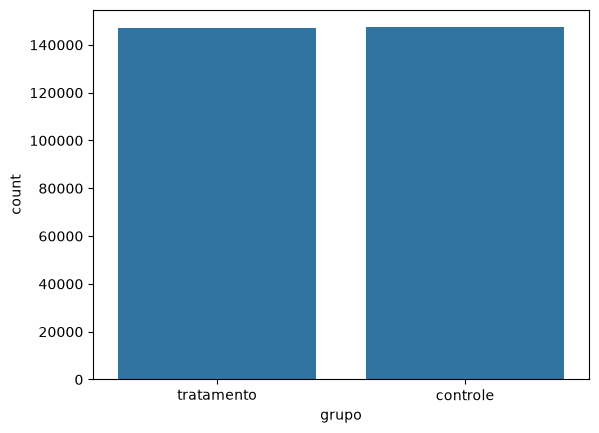

In [5]:
sns.countplot(data=data, x='grupo')

In [8]:
# Verficando a taxa de conversão por grupo
print(pd.crosstab(data["grupo"], data["converteu"]))

converteu        0      1
grupo                    
controle    129756  17514
tratamento  129467  17723


In [9]:
# Taxa de conversão por grupo em porcentagem
conversion_rate = data.groupby('grupo')['converteu'].mean() * 100
print(conversion_rate)

grupo
controle      11.892442
tratamento    12.040900
Name: converteu, dtype: float64


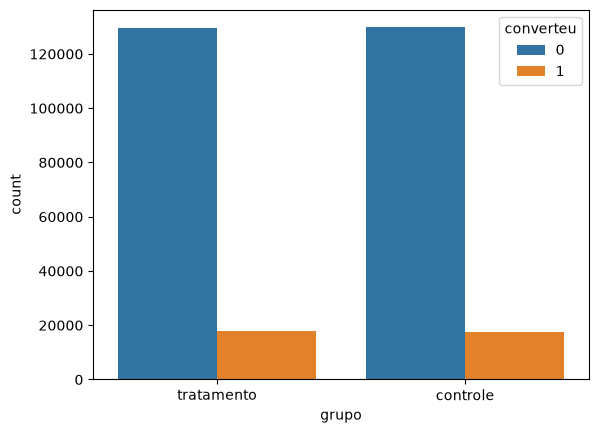

In [10]:
# Distribuição de conversão por grupo
sns.countplot(data=data, x='grupo', hue='converteu')
plt.show()

In [11]:
# Relação entre grupo e página
print(pd.crosstab(data["grupo"], data["pagina"]))

pagina      pagina_com_cta  pagina_sem_cta
grupo                                     
controle              1965          145305
tratamento          145262            1928


Tem erro. O grupo de controle não deveria ter página com cta, e vice-versa.

In [12]:
# Verificando se o número de observações nos grupos é balanceado
print("Número de observações no grupo de controle:", len(data[data['grupo'] == 'controle']))
print("Número de observações no grupo de tratamento:", len(data[data['grupo'] == 'tratamento']))

Número de observações no grupo de controle: 147270
Número de observações no grupo de tratamento: 147190


In [13]:
# Filtrando os dados para garantir a consistência entre grupo e página
data_filtered = data[
    ((data['grupo'] == 'controle') & (data['pagina'] == 'pagina_sem_cta')) |
    ((data['grupo'] == 'tratamento') & (data['pagina'] == 'pagina_com_cta'))
]

In [14]:
data_filtered.shape

(290567, 5)

In [15]:
# Nova taxa de conversão por grupo em porcentagem após filtragem
conversion_rate_filtered = data_filtered.groupby('grupo')['converteu'].mean() * 100
print(conversion_rate_filtered)

grupo
controle      11.881215
tratamento    12.039625
Name: converteu, dtype: float64


Proporção segue a mesma. Diferença entre os grupos aparentemente é marginal.

# Teste A/B com Métodos Estatísticos

(*H0) Hipótese nula*: não existe associação entre as variáveis 'grupo' e 'converteu'. O usuário pertencer a um grupo ou outro não afeta a probabilidade de conversão.

(*H1) Hipótese alternativa*: existe uma associação entre as variáveis 'grupo' e 'converteu'. O usuário pertencer a um grupo ou outro influencia a probabilidade de conversão.

## Qui-Quadrado

Determina se há associação significativa entre duas variáveis categóricas. É amplamente utilizado para testar hipóteses sobre a independência de variáveis em tabelas de contingência (tabelas que mostram a distribuição de frequências de variáveis).

In [16]:
# Carregando a biblioteca
from scipy.stats import chi2_contingency

In [17]:
# Construção da tabela de contingência
contingency_table = pd.crosstab(data_filtered['grupo'], data_filtered['converteu'])

In [18]:
# Aplicando o teste qui-quadrado
chi2, p_value, _, _ = chi2_contingency(contingency_table)
print(f"Chi-square: {chi2}")
print(f"P-value: {p_value}")

Chi-square: 1.7161007736557263
P-value: 0.19019573569633683


In [19]:
# Conclusão da significância estatística com p-valor
if p_value < 0.05:
    print("Há evidência estatística significativa para rejeitar a hipótese nula.")
else:
    print("Não há evidência estatística significativa para rejeitar a hipótese nula.")

Não há evidência estatística significativa para rejeitar a hipótese nula.


O resultado do teste indica que não há diferença significativa entre os grupos.

## T de Student

Método usado para comparar as médias de duas amostras independentes para determinar se há uma diferença estatisticamente significativa entre elas. AMplamente utilizado em comparações entre dois grupos distintos. 

Para sua devida aplicação, algumas suposições devem ser satisfeitas:
* Independencia das observações: as amostrar devem ser coletadas de forma independente uma da outra;
* Normalidade: as distribuições das duas populações devem ser aproximadamente normais. Amostras grandes não preocupam, considerando o Teorema do Limite Central;
* Homogeneidade das variâncias: as variâncias das duas populações devem ser iguais. Quando as variâncias não são iguais, variantes do teste em questão, como o teste de Welch, devem ser aplicadas.

In [20]:
# Separando os grupos de controle e tratamento
control_group = data_filtered[data_filtered['grupo'] == 'controle']
treatment_group = data_filtered[data_filtered['grupo'] == 'tratamento']

In [21]:
# Média das taxas de conversão para cada grupo
control_conversion_rate = control_group['converteu'].mean()
treatment_conversion_rate = treatment_group['converteu'].mean()

print(f"Taxa de conversão do grupo de controle: {control_conversion_rate * 100:.2f}%")
print(f"Taxa de conversão do grupo de tratamento: {treatment_conversion_rate * 100:.2f}%")

Taxa de conversão do grupo de controle: 11.88%
Taxa de conversão do grupo de tratamento: 12.04%


In [23]:
# Aplicando o teste
t_stat, p_value = stats.ttest_ind(control_group['converteu'], treatment_group['converteu'])
print(f"Statistic: {t_stat}")
print(f"P-value: {p_value}")

Statistic: -1.315716642446585
P-value: 0.1882702043077206


In [26]:
# Conclusão da significância estatística com p-valor
if p_value < 0.05:
    print("Há evidência estatística significativa para rejeitar a hipótese nula.")
else:
    print("Não há evidência estatística significativa para rejeitar a hipótese nula.")

Não há evidência estatística significativa para rejeitar a hipótese nula.


Resultado alinhado com o teste anterior.

### Testando normalidade das amostras

H0: Os dados seguem uma distribuição normal;

H1: Os dados não seguem uma distribuição normal.

In [27]:
# Importando a biblioteca
from scipy.stats import shapiro

In [28]:
# Aplicando o teste de Shapiro-Wilk para verificar a normalidade dos dados
stat_A, p_A = shapiro(control_group['converteu'])
stat_B, p_B = shapiro(treatment_group['converteu'])

print(f"Shapiro-Wilk - Grupo A: Statistic={stat_A}, P-value={p_A}")
print(f"Shapiro-Wilk - Grupo B: Statistic={stat_B}, P-value={p_B}")

Shapiro-Wilk - Grupo A: Statistic=0.37688432197636845, P-value=2.852310563431821e-178
Shapiro-Wilk - Grupo B: Statistic=0.37962250494140426, P-value=4.133478884023201e-178


In [29]:
# Interpretando os resultados

alpha = 0.05

if p_A > alpha:
    print("Grupo A: Os dados seguem uma distribuição normal (não rejeitamos H0).")
else:
    print("Grupo A: Os dados não seguem uma distribuição normal (rejeitamos H0).")

if p_B > alpha:
    print("Grupo B: Os dados seguem uma distribuição normal (não rejeitamos H0).")
else:
    print("Grupo B: Os dados não seguem uma distribuição normal (rejeitamos H0).")

Grupo A: Os dados não seguem uma distribuição normal (rejeitamos H0).
Grupo B: Os dados não seguem uma distribuição normal (rejeitamos H0).


Apesar do teste em questão concordar com o teste anteriormente aplicado, dado que uma de suas suposições não foram atendidas, as conclusões deste teste não devem ser consideradas para uma tomada de decisão.

Uma vez não seguindo normalidade, vamos atacar outro teste não paramétrico.

## Mann-Whitney - U

Teste não paramétrico utilizado para comparar as medianas de duas amostras independentes. É especialmente útil quando as premissas de normalidade dos dados não são atendidas, o que é comum em muitas situações práticas. É uma alternativa ao T de Student para amostras em que os dados não são normalmente distribuídos.

In [32]:
# Importanto a biblioteca
from scipy.stats import mannwhitneyu

In [33]:
# Aplicando o teste de Mann-Whitney
u_statistic, p_value_mw = mannwhitneyu(control_group['converteu'], treatment_group['converteu'], alternative='two-sided')

Neste caso, alternative='two_sided' especifica que o teste é bicaudal, o que é equivalente ao teste t bicaudal. É o mais adequado quando não se tem uma hipóteses específica sobre a direção da diferença entre os grupos.

In [ ]:
# Resultados do teste de Mann-Whitney
print(f"Mann-Whitney U Statistic: {u_statistic}")
print(f"P-value: {p_value_mw}")

Mann-Whitney U Statistic: 10536929466.5
P-value: 0.1882697352188082


In [35]:
# Interpretação do resultado
alpha = 0.05
if p_value_mw < alpha:
    print("Há evidência estatística significativa para rejeitar a hipótese nula: não há diferença significativa entre a mediana das taxas de conversão dos grupos.")
else:
    print("Não há evidência estatística significativa para rejeitar a hipótese nula: não há diferença significativa entre a mediana das taxas de conversão dos grupos.")

Não há evidência estatística significativa para rejeitar a hipótese nula: não há diferença significativa entre a mediana das taxas de conversão dos grupos.


# Teste A/B com Regressão Logística

Método utilizado para modelar a probabilidade de um evento ocorrer, com base na relação entre a variável dependente binária e uma ou mais variáveis independentes.

In [38]:
# Importando a biblioteca
from sklearn.linear_model import LogisticRegression

## Preparando os dados para o modelo de regressão logística

In [39]:
# Coluna dummy onde 1 = "pagina_com_cta" e 0 = "pagina_sem_cta"
data_filtered['pagina_dummy'] = np.where(data_filtered['pagina'] == 'pagina_com_cta', 1, 0)

In [40]:
# Definindo a variável dependente (y) e a variável independente (X)
y = data_filtered['converteu']
X = data_filtered[['pagina_dummy']]

In [41]:
# Ajustando/fitando o modelo de regressão logística
model = LogisticRegression()
model.fit(X, y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [ ]:
# Coeficientes do modelo
coef = model.coef_[0][0]
odds_ratio = np.exp(coef)
print(f"Coeficiente: {coef}") # também conhecido como logit
print(f"Odds Ratio: {odds_ratio}")

Coeficiente: 0.015575832009267345
Odds Ratio: 1.0156977675405237


## Interpretação

*Log-odds (coeficientes)*: representam o efeito de uma unidade de mudança na variável independente sobre o log-odds da variável dependente (y). Um valor positivo indica que conforme a variável independente aumenta, o log-odds da dependente aumenta também, e vice-versa.

*Odds ratios*: obtidas ao exponenciar os coeficientes d modelo. Representa o fator de mudança nas odds da variável dependente em resposta a uma unidade de mudança na independente:
* OR = 1: a variável independente não tem efeito sobre a dependente;
* OR > 1: a variável independente tem efeito positivo sobre a dependente;
* OR < 1: a variável independente tem efeito negativo sobre a dependente.

Sendo assim, um odds-ratio de aproximadamente 1.015 indica que a presença de um CTA na página multiplica as odds de conversão por aproximadamente 1.015. Isso indica que, estando presente o CTA, as odds de conversão são 1.5% mais altas do que quando não está presente.

Apesar de não tendo diferença significativa, ainda é uma mudança positiva, indicando que a presença de um CTA tem um impacto ligeiramente positivo na probabilidade de conversão.